In [20]:
! pip install PyMPDATA

In [21]:
import PyMPDATA
import numpy as np

In [22]:
print(np.__file__)

/usr/local/lib/python3.13/dist-packages/numpy/__init__.py
/usr/local/lib/python3.13/dist-packages/numpy/__init__.py


In [40]:
from PyMPDATA import ScalarField, VectorField, Options, boundary_conditions as bc

options = Options(n_iters=4, infinite_gauge=True, nonoscillatory=True, third_order_terms=True)
common = {
    'halo': options.n_halo,
    'boundary_conditions': (bc.Periodic(),)
}

psi = ScalarField(**common, data=(np.exp(-(x:=np.linspace(-2, 8, 41))**2)))  # pole skalarne
C = VectorField(**common, data=(np.full(x.size+1, 1/4),))  # pole wektorowe, liczba couranta

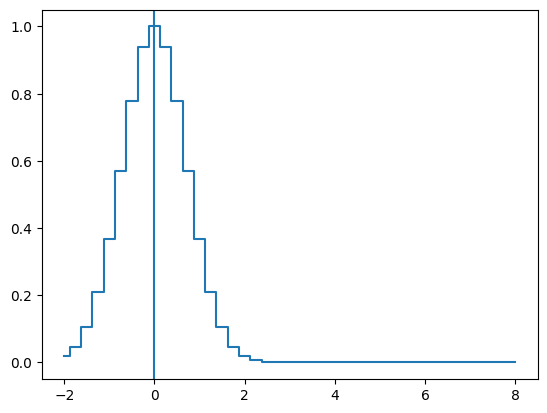

In [41]:
from matplotlib import pyplot

#pyplot.plot(x, psi.get())
pyplot.step(x, psi.get(), where='mid')
pyplot.axvline(0)

In [50]:
from PyMPDATA import Stepper, Solver

solver = Solver(advector=C, advectee=psi, stepper=Stepper(n_dims=1, options=options))
solver.advance(520)

123355.9173076923

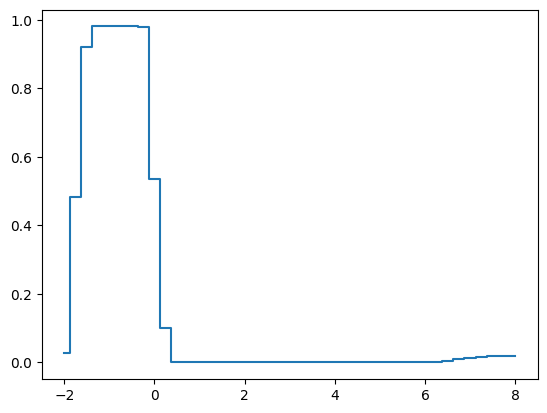

In [51]:
pyplot.step(x, psi.get(), where='mid')